<a href="https://colab.research.google.com/drive/1DRmUujuHdM50KpItIyBeW6MJUcaZQamM" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>  
(Ссылка обновлена, ноутбук загружен в Colab)

# **Домашнее задание №1 (base)**

В этом домашнем задании вам будет необходимо:
*  обучить модель регрессии для предсказания стоимости автомобилей;

**Оценивание**

Максимальная оценка за ДЗ — **10 баллов**:
- Части 1–4 (EDA, модели, категориальные признаки, бизнес-метрика) — 5 баллов;
- Часть 5, оформление репозитория — 2 балла;
- Часть 6, Streamlit-приложение — 3 балла.

**Дедлайн: 2 декабря**

**Примечание**

В каждой части оцениваются как код, **так и ответы на вопросы.**

Если нет одного и/или другого, то часть баллов за соответствующее задание снимается.

In [1]:
# !pip install -q ydata-profiling "numpy<2.4"  # numba в Colab пока не поддерживает NumPy 2.4
%pip install -q ydata-profiling "numpy<2.4"
%pip install "setuptools<81"
%pip install ipywidgets
%matplotlib inline


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import seaborn as sns
from ydata_profiling import ProfileReport

from sklearn.linear_model import LinearRegression, Lasso, ElasticNet, Ridge
from sklearn.metrics import r2_score, mean_squared_error as MSE
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # для OHE можно использовать и pd.get_dummies

random.seed(42)
np.random.seed(42)

/var/folders/fj/f8byv04d4fx7txz67j86042w0000gn/T/ipykernel_80363/2223499982.py:6: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [3]:
pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)

Давайте зафиксируем важный момент.

**Задание 0 (0 баллов).**
Изучите и ответьте на вопрос: для чего фиксируем сиды в домашках?

Чтобы результаты были воспроизводимы и одинаковы у всех участников.

# **Часть 1 | EDA и визуализация**

Первая часть состоит из классических шагов EDA:

- Базовый EDA и обработка признаков (1.5 балла)
- Визуализации признаков и их анализ (1 балл)

Всего за эту часть можно набрать 2.5 балла.

## **Простейший EDA и обработка признаков (1.5 балла)**

In [4]:
df_train = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_train.csv')
df_test = pd.read_csv('https://raw.githubusercontent.com/Murcha1990/MLDS_ML_2022/main/Hometasks/HT1/cars_test.csv')

print("Train data shape:", df_train.shape)
print("Test data shape: ", df_test.shape)

Train data shape: (6999, 13)
Test data shape:  (1000, 13)


### **Задание 1 (0.45 балла)**

Вы уже встречались с pandas в первой половине семестра. Теперь будем постоянно (кроме некоторых случаев) использовать его для анализа данных и наслаивать навыки. Выполните операции, направленные на практику основных действий с `pandas`:

**0.1 балла**
- [+] Отобразите 30 случайных строк тренировочного датасета.
- [+] Отобразите первые 5 и последние 5 объектов тестового датасета
- [+] Посмотрите, есть ли в датасете пропуски. Запишите/выведите названия колонок, для которых есть пропущенные значения
- [+] Посмотрите, есть ли в данных явные дубликаты


**0.2 балла**
Ответьте на вопросы:
- [+] О чём можно сделать выводы, используя случайные/верхние/нижние строки? А о чем нельзя?
- [+] Достаточно ли метода duplicated для анализа дубликатов? Почему?

**0.15 балла**
- [+] Постройте дашборд, используя [ydata-profiling](https://github.com/ydataai/ydata-profiling)

In [5]:
print("30 random df_train rows:")
print(pd.DataFrame(df_train.sample(30)))

print("\nFirst five df_train rows:")
print(df_train.head())
print("\nLast five df_test rows:")
print(df_test.tail())

# print(df_train.info())
mask = df_train.isna().sum()
print("\nColumns with missing values:", ", ".join(mask[mask > 0].index))

mask = df_train.duplicated()
print("Rows with duplicates in dataset:", len(df_train[mask].index))
print("\n")

profile = ProfileReport(df_train, title="Profiling Report")
profile
# profile.to_file("report.html")

30 random df_train rows:
                                        name  year  selling_price  km_driven    fuel       seller_type transmission         owner     mileage   engine   max_power                  torque  seats
6565        Renault KWID Climber 1.0 MT BSIV  2019         300000      35000  Petrol        Individual       Manual   First Owner  23.01 kmpl   999 CC      67 bhp           91Nm@ 4250rpm    5.0
2943                      Maruti Wagon R LXI  2013         225000      58343  Petrol  Trustmark Dealer       Manual   First Owner  21.79 kmpl   998 CC   67.05 bhp           90Nm@ 3500rpm    5.0
2024                    Hyundai i20 Asta 1.2  2013         360000      30000  Petrol        Individual       Manual   First Owner   18.5 kmpl  1197 CC   82.85 bhp        113.7Nm@ 4000rpm    5.0
263                     Hyundai i20 1.2 Asta  2010         300000      70000  Petrol        Individual       Manual   First Owner   17.0 kmpl  1197 CC      80 bhp   11.4 kgm at 4,000 rpm    5.0
4586 

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 13/13 [00:00<00:00, 100601.39it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Ответы на вопросы:
- Используя случайные/верхние/нижние строки можно узнать, как выглядят значения в столбцах, в каком они формате, какие значения примерно могут принимать. Если посмотреть только по `head/tail` без `sample`, можно сделать ложные выводы из-за отсортированности датасета. Не получится узнать про значения всей таблицы, например про количество пропусков в столбцах и строках, число дублей, реальные типы данных (может быть написано числом, а на самом деле тип данных - `object`).
- Недостаточно, так как duplicated проверяет точное совпадение строк, а у нас один и тот же автомобиль может стоить по-разному.

In [6]:
print("Train set numeric statistics:")
print(df_train.describe(include='number'))
print("\nTest set numeric statistics:")
print(df_test.describe(include='number'))

print("\nTrain set object statistics:")
print(df_train.describe(include='object'))
print("\nTest set object statistics:")
print(df_test.describe(include='object'))

Train set numeric statistics:
              year  selling_price     km_driven        seats
count  6999.000000   6.999000e+03  6.999000e+03  6797.000000
mean   2013.818403   6.395152e+05  6.958462e+04     5.419008
std       4.053095   8.089419e+05  5.772400e+04     0.965767
min    1983.000000   2.999900e+04  1.000000e+00     2.000000
25%    2011.000000   2.549990e+05  3.500000e+04     5.000000
50%    2015.000000   4.500000e+05  6.000000e+04     5.000000
75%    2017.000000   6.750000e+05  9.700000e+04     5.000000
max    2020.000000   1.000000e+07  2.360457e+06    14.000000

Test set numeric statistics:
              year  selling_price      km_driven       seats
count  1000.000000   1.000000e+03    1000.000000  981.000000
mean   2013.681000   6.179010e+05   71393.341000    5.410805
std       4.012149   7.585539e+05   48486.218662    0.919985
min    1995.000000   3.100000e+04    1303.000000    4.000000
25%    2011.000000   2.500000e+05   37000.000000    5.000000
50%    2014.000000   4.34

### **Задание 2 (0.5 балла)**

На прошлом шаге вы рассмотрели дубликаты. Однако дубликат может быть связан не только с полным повторением информации в нескольких строках, но и частичным. Например, объект мог быть внесён в базу данных с разным значением целевой переменной. В этом шаге займемся такими дублями!

**Ваши действия:**

- [+] Посмотрите, есть ли в трейне объекты с одинаковым признаковым описанием (целевую переменную следует исключить). Если есть, то сколько? (0.1 балла)
- [+] Отобразите такие объекты (0.15 балла)
- [+] Удалите повторяющиеся строки. Если при одинаковом признаковом описании цены на автомобили отличаются, то оставьте первую строку по этому автомобилю (0.15 балла)
- [+]  Обновите индексы строк таким образом, чтобы они шли от 0 без пропусков (0.1 балла)


In [7]:
target = df_train['selling_price']
df_train_no_target = df_train.drop(['selling_price'], axis=1)

print("Rows with duplicates:", df_train_no_target.duplicated().sum())

df_train_no_target_duplicated = df_train_no_target[df_train_no_target.duplicated()]
print("\nDuplicated rows:")
print(df_train_no_target_duplicated)

df_train = df_train.drop(df_train_no_target_duplicated.index, axis=0)

df_train = df_train.reset_index(drop=True)

Rows with duplicates: 1159

Duplicated rows:
                                          name  year  km_driven    fuel seller_type transmission         owner     mileage   engine   max_power               torque  seats
254                   Hyundai Grand i10 Sportz  2017      35000  Petrol  Individual       Manual   First Owner   18.9 kmpl  1197 CC      82 bhp       114Nm@ 4000rpm    5.0
258                           Maruti Swift VXI  2012      50000  Petrol  Individual       Manual  Second Owner   18.6 kmpl  1197 CC    85.8 bhp       114Nm@ 4000rpm    5.0
268                     Maruti Swift Dzire VXI  2014      70000  Petrol  Individual       Manual  Second Owner   19.1 kmpl  1197 CC    85.8 bhp       114Nm@ 4000rpm    5.0
324   Jaguar XE 2016-2019 2.0L Diesel Prestige  2017       9000  Diesel      Dealer    Automatic   First Owner   13.6 kmpl  1999 CC     177 bhp  430Nm@ 1750-2500rpm    5.0
325                              Lexus ES 300h  2019      20000  Petrol      Dealer    Automati

In [8]:
assert df_train.shape == (5840, 13)

Отлично! Мы избавились от маленьких и явных проблем. Теперь перейдем к более сложным недостаткам полученной таблицы.

### **Задание 3 (0.25 балла)**

Вы могли заметить, что с признаками ``mileage, engine, max_power и torque`` всё не очень хорошо. Они распознаются как строки (можно убедиться в этом, вызвав `data.dtypes`). Однако эти переменные не являются категориальными — они — числа. Соответственно, нужно привести их к числовому виду.

**Задача:**
* [+] Уберите единицы измерения для признаков ``mileage, engine, max_power``.
* [+] Приведите тип данных к ``float``.
* [+] Удалите столбец ``torque``


**Важно**
- Все действия нужно производить над обоими датасетами — `train` и `test`.
- Столбец ``torque`` мы удаляем для простоты. В идеальном случае, его также стоило бы предобработать.

In [9]:
df_train = df_train.drop(['torque'], axis=1)
df_test = df_test.drop(['torque'], axis=1)

cols_to_numeric = ['mileage', 'engine', 'max_power']
for name, df in (('train', df_train), ('test', df_test)):
    bad = {}
    for col in cols_to_numeric:
        s = df[col]
        parsed = pd.to_numeric(s.str.split().str[0], errors='coerce')
        bad[col] = s[parsed.isna() & s.notna()].unique()
    print(f"Wrong written values in {name} set:", bad)

for df in (df_train, df_test):
    for col in cols_to_numeric:
        df[col] = pd.to_numeric(df[col].str.split().str[0], errors='coerce')

print("\nTrain set dtypes:")
print(df_train.dtypes)
print("\nTest set dtypes:")
print(df_test.dtypes)

Wrong written values in train set: {'mileage': array([], dtype=object), 'engine': array([], dtype=object), 'max_power': array([' bhp'], dtype=object)}
Wrong written values in test set: {'mileage': array([], dtype=object), 'engine': array([], dtype=object), 'max_power': array([], dtype=object)}

Train set dtypes:
name              object
year               int64
selling_price      int64
km_driven          int64
fuel              object
seller_type       object
transmission      object
owner             object
mileage          float64
engine           float64
max_power        float64
seats            float64
dtype: object

Test set dtypes:
name              object
year               int64
selling_price      int64
km_driven          int64
fuel              object
seller_type       object
transmission      object
owner             object
mileage          float64
engine           float64
max_power        float64
seats            float64
dtype: object


### **Задание 4 (0.15 балла)**

В Задании 1 мы обнаружили пропуски. Давайте избавимся от них.

**Шаг 1 (0.05 балла)**
- [+] Заполните пропуски в столбцах медианами. Убедитесь, что после заполнения пропусков не осталось. Заполнение пропусков проводите для обоих наборов данных, если необходимо

**Важно!**

При заполнении пропусков и в тестовом, и тренировочном наборах данных вы определяетесь со стратегией предобработки пропущенных значений при потенциальной работе модели.

Так как в теоретическом случае вы не имеете доступа к тестовой выборке, то заполняемое значение (у нас — медиана) вы считаете по *тренировочному* набору данных и им же заполняете *тестовый*.

In [10]:
numeric_cols = df_train.select_dtypes(include='number').columns.to_list()
for col in df_train[numeric_cols]:
    median = df_train[col].median(skipna=True)
    df_train[col] = df_train[col].fillna(median)
    df_test[col] = df_test[col].fillna(median)

print("Train set nulls:")
print(df_train.isna().sum())
print("\nTest set nulls:")
print(df_test.isna().sum())

Train set nulls:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
seats            0
dtype: int64

Test set nulls:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
seats            0
dtype: int64


**Шаг 2 (0.1 балла)**

Теперь, когда не осталось пропусков, давайте преобразуем столбцы к более подходящим типам. А именно столбцы ``engine`` и ``seats`` приведём к `int`.

- [+] Осуществите приведение столбцов к необходимому типу.

In [11]:
cols_to_int = ['engine', 'seats']
df_train[cols_to_int] = df_train[cols_to_int].astype(int)
df_test[cols_to_int] = df_test[cols_to_int].astype(int)

### **Задание 5 (0.15 балла)**

Отлично! Мы провели "косметическую" предобработку и теперь готовы сделать важный шаг в контексте анализа данных. А именно — посмотреть на статистики!

**Ваша задача:**
- [+] Посчитайте основные статистики по числовым столбцам для трейна и теста
- [+] Посчитайте основные статистики по категориальным столбцам для трейна и теста
- [+] Сделайте вывод.

**Подсказка:**

Используйте ``.describe()`` с нужным(и) аргументом(-ами).

**Примечание:**

Более корректно рассматривать статистики до заполнения пропусков и после, чтобы убедиться, что мы не внесли каких-либо серьезных сдвигов в изначальные распределения.

In [12]:
print("Train set numeric statistics:")
print(df_train.describe(include='number'))
print("\nTest set numeric statistics:")
print(df_test.describe(include='number'))

print("\nTrain set object statistics:")
print(df_train.describe(include='object'))
print("\nTest set object statistics:")
print(df_test.describe(include='object'))

Train set numeric statistics:
              year  selling_price     km_driven      mileage       engine    max_power        seats
count  5840.000000   5.840000e+03  5.840000e+03  5840.000000  5840.000000  5840.000000  5840.000000
mean   2013.428425   5.229601e+05  7.395224e+04    19.430841  1429.448973    87.906371     5.426712
std       4.095622   5.354320e+05  6.007114e+04     3.985973   485.662834    31.640418     0.982344
min    1983.000000   2.999900e+04  1.000000e+00     0.000000   624.000000     0.000000     2.000000
25%    2011.000000   2.500000e+05  3.900000e+04    16.950000  1197.000000    68.000000     5.000000
50%    2014.000000   4.050000e+05  7.000000e+04    19.370000  1248.000000    81.860000     5.000000
75%    2017.000000   6.400000e+05  1.000000e+05    22.300000  1498.000000    99.000000     5.000000
max    2020.000000   1.000000e+07  2.360457e+06    42.000000  3604.000000   400.000000    14.000000

Test set numeric statistics:
              year  selling_price      k

Выводы:
- Из тренировочного датасета были удалены 1159 строк дубликатов, заполнены 202 строки с пропусками; в тестовом датасете удаление строк не произошло, а вот заполнены были 19 строк с пустыми значениями.
- К числовым столбцам добавились 3 столбца - 'mileage', 'engine', 'max_power'.
- Из-за удаления дубликатов в тренировочном датасете средняя цена продажи автомобиля снизилась с 639 тыс. до 523 тыс., а медиана - с 450 тыс. до 405 тыс.
- Также я заметил в `max_power` нули, что скорее всего является пропусками, но обрабатывать их по заданию не стал.

In [13]:
# torque удалён в Задании 3, поэтому столбцов 12
assert df_train.shape == (5840, 12)

## **Визуализации (1 балл)**

Визуализация данных — важный шаг в работе. Визуализировать данные необходимо, например, чтобы:

- Оценить распределения признаков самих по себе (это может натолкнуть вас на мысли о модели, которую можно использовать)
- Сравнить распределения на `train` и `test` — чтобы проверить, насколько информация, на которой вы будете обучаться согласуется с той, на которой модель должна работать
- Оценить есть ли явная связь признаков с целевой переменной

**Важно:**

Если распределения на `train` и `test` не совпадают, это не значит, что нужно перемешивать данные! Более корректно актуализировать задачу и уточнить, а не устарели ли данные `train`.

**Если вы будете подгонять распределения, то можете встретиться с переобучением!**

### **Задание 6 (0.4 балла)**

Шаг 1.
- [+] Воспользуйтесь `pairplot` из библиотеки `seaborn`, чтобы визуализировать попарные распределения числовых признаков для `train`
- [+] По полученному графику ответьте на вопросы:
 - Можно ли предположить на основе распределений связь признаков с целевой переменной?
 - Можно ли на основе распределений выдвинуть гипотезу о корреляциях признаков?

Шаг 2.

- [+] Постройте pairplot по тестовым данным
- [+] Ответьте на вопрос "Похожими ли оказались совокупности при разделении на трейн и тест?"

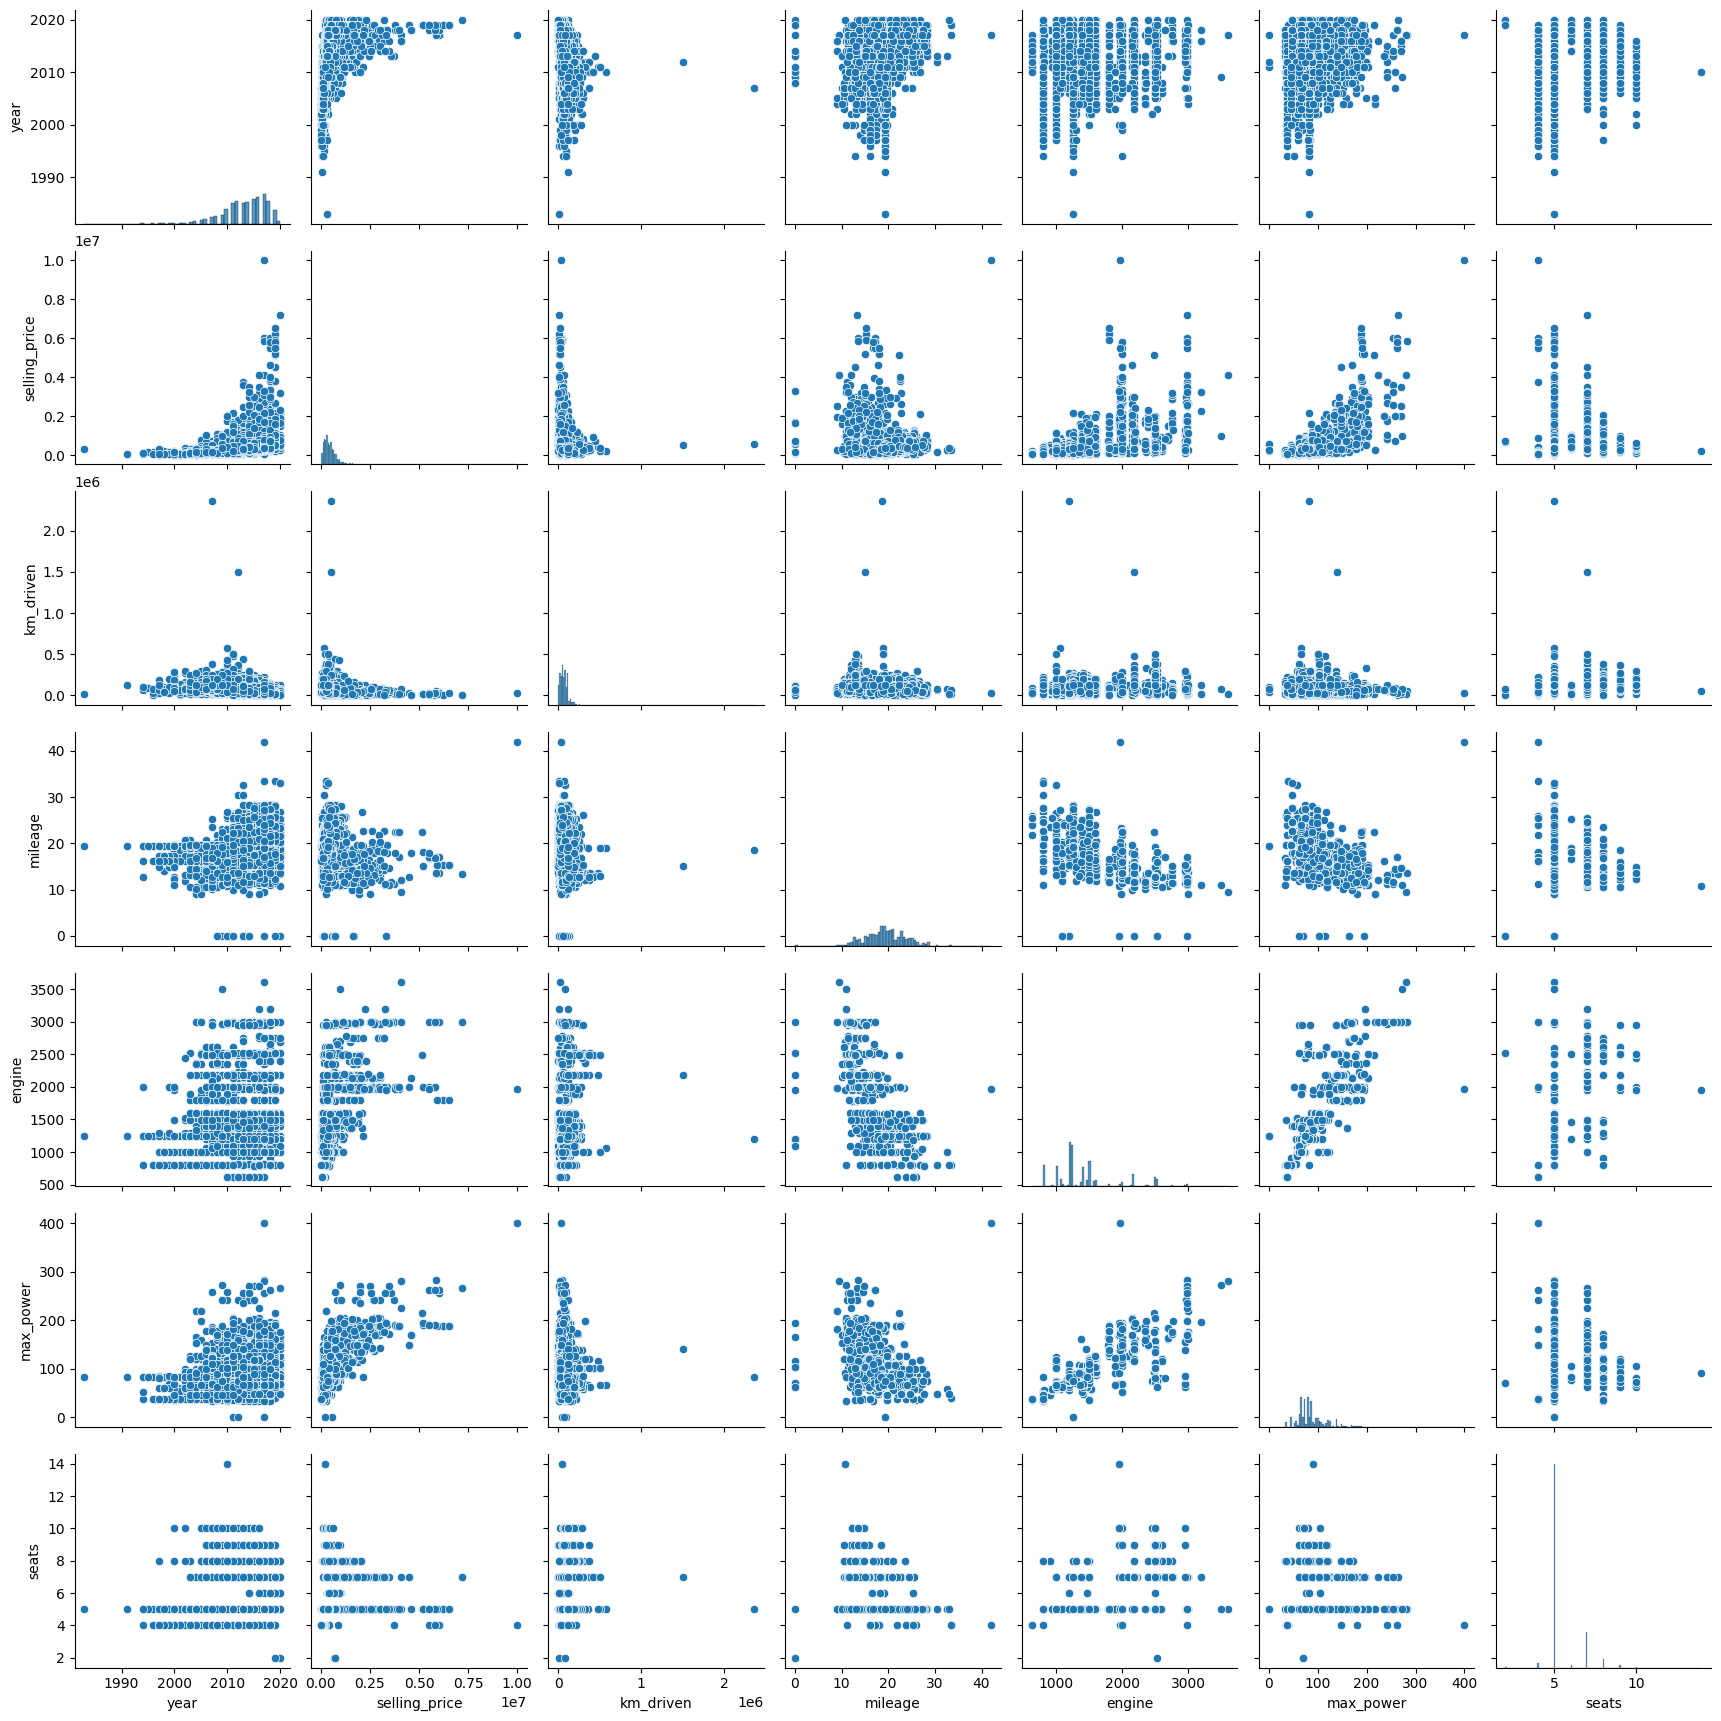

In [14]:
sns.pairplot(df_train);

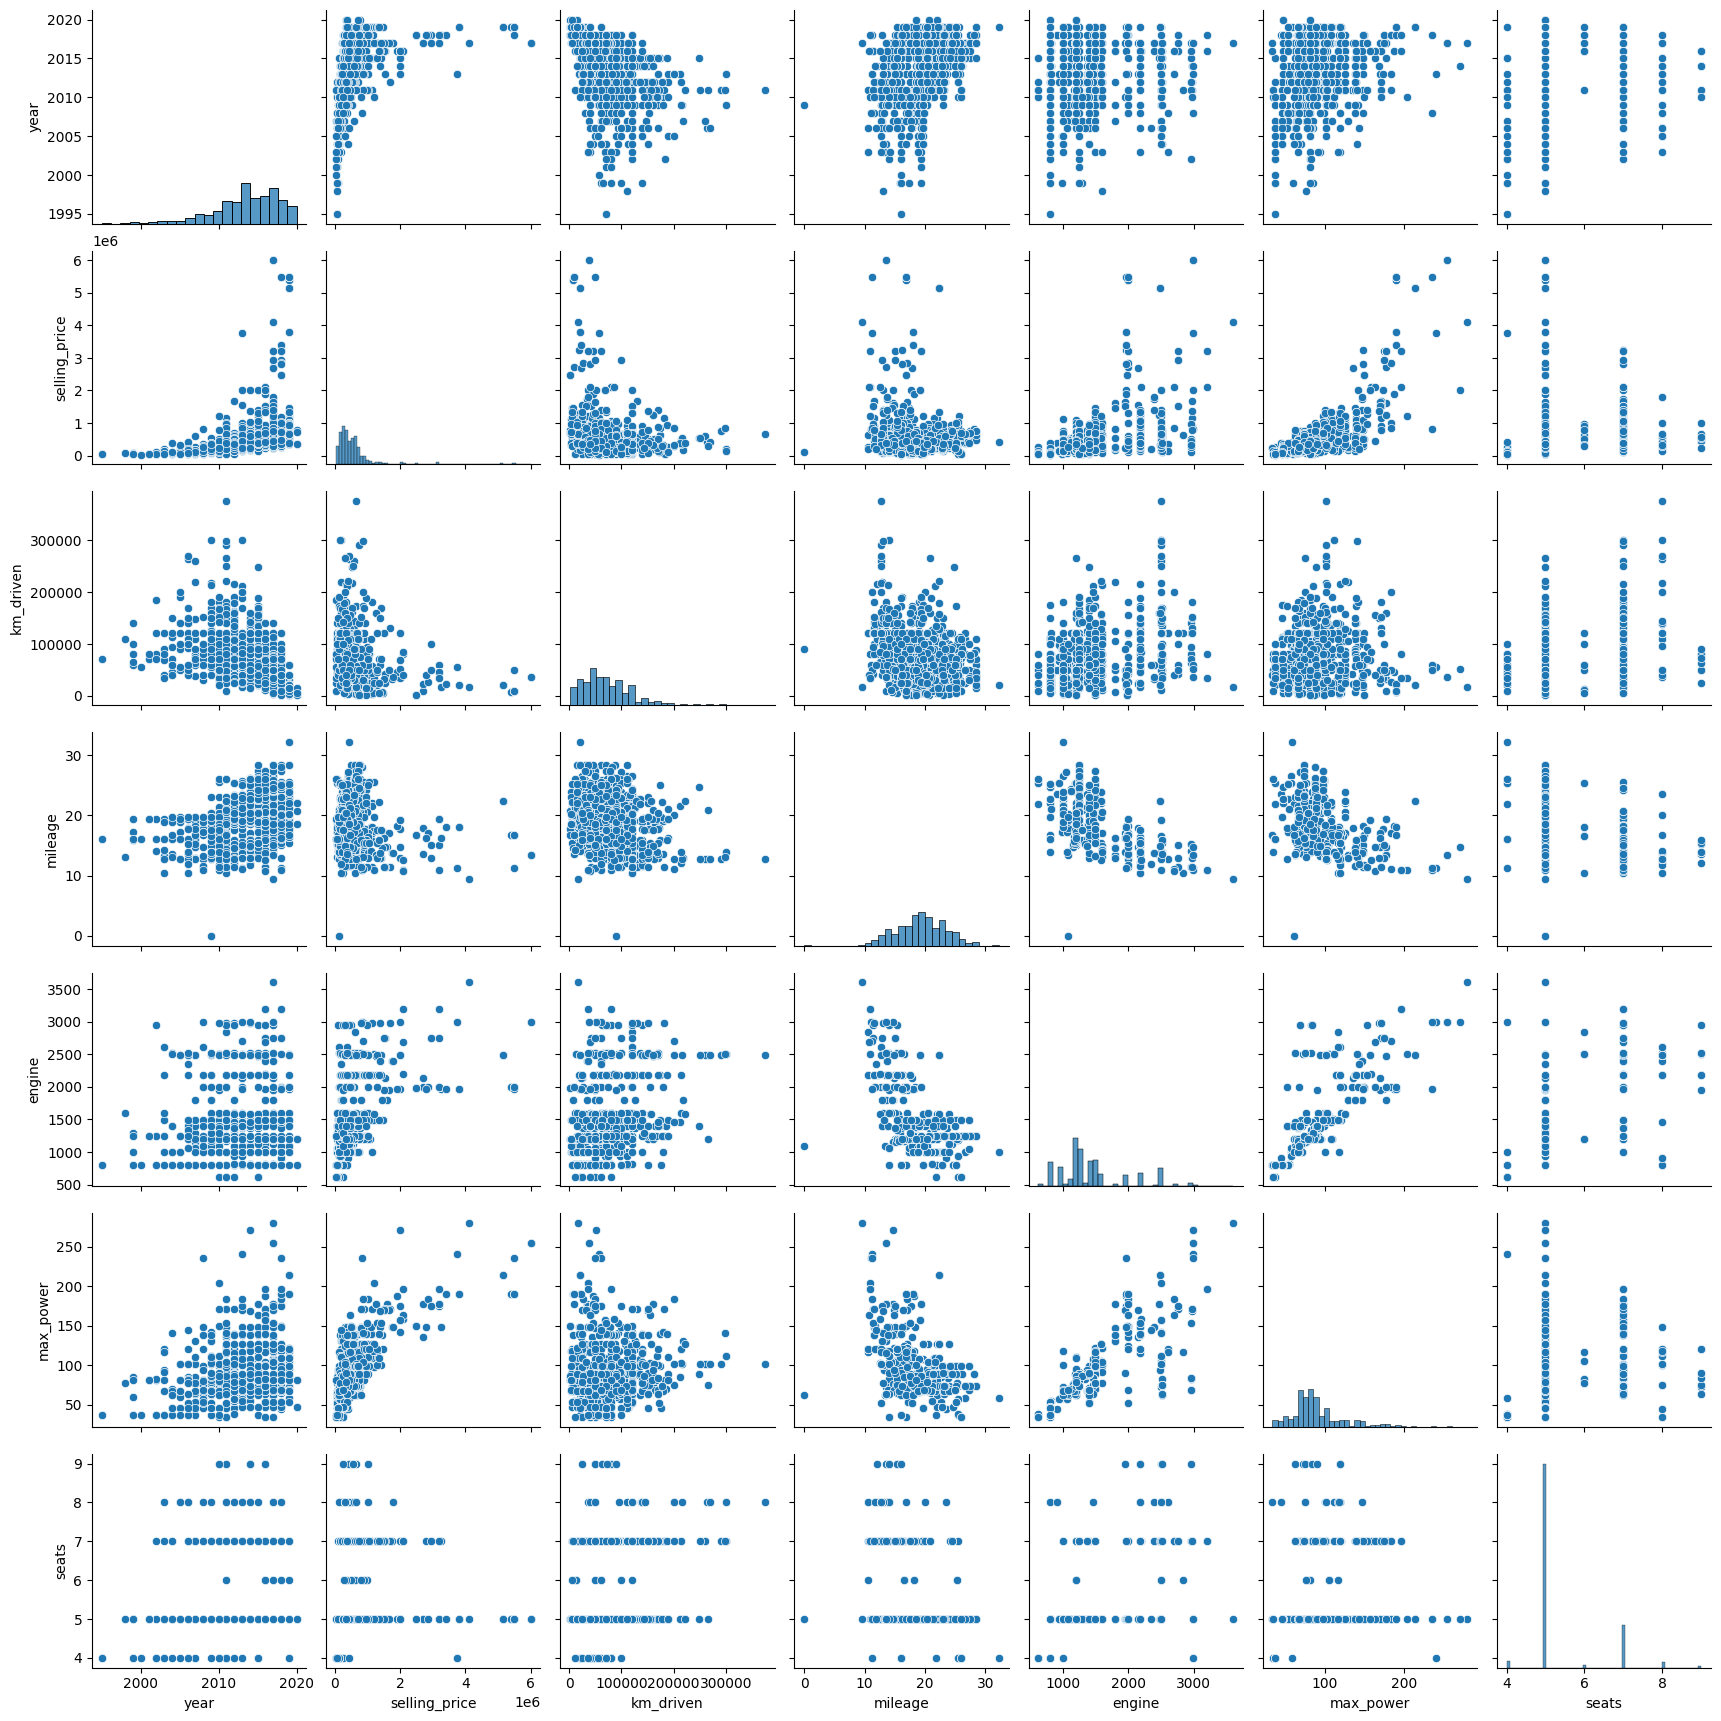

In [15]:
sns.pairplot(df_test);

Ответы на вопросы:
- Да, можно предположить, что с каждым годом появляется все больше дорогих автомобилей, что при меньшем `km_driven` больше дорогих продаж, что чем больше значения `engine` и `max_power`, тем, зачастую, больше цена продажи.
- Можно предположить прямую корреляцию между `max_power` и `engine`, что логично. Больше четких корреляций я не заметил.
- Совокупности при разделении являются похожими. Их графики `pairplot` практически идентичны.

### **Задание 7 (0.35 балла)**

Итак, вы выдвинули гипотезы о наличии связи. Теперь давайте оценим эту связь в числах.

**Задание:**
- [+] Получите значения коэффициента корреляции Пирсона для тренировочного набора данных при помощи `DataFrame.corr()`
- [+] По полученным корреляциям постройте тепловую карту (`heatmap` из библиотеки seaborn)

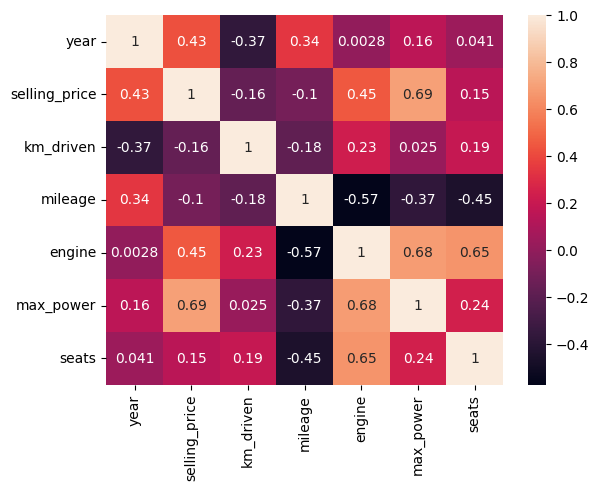

In [16]:
pearson_corr = df_train.corr(numeric_only=True)
sns.heatmap(pearson_corr, annot=True);

- [+] Ответьте на вопросы:
 - Какие 2 признака наименее скоррелированы между собой?
 - Между какими наблюдается довольно сильная положительная линейная зависимость?
 - Правильно ли, опираясь на данные, утверждать, что чем меньше год, тем, скорее всего, больше километров проехала машина к дате продажи?

Ответы на вопросы:
- `engine` и `year` наименее скоррелированы между собой - коэффициент корреляции = 0.0028.
- Сильная положительная зависимость наблюдается между `selling_price` и `max_power`, между `engine` и `seats`, а также между `max_power` и `engine`.
- Можно сказать, что чем меньше год, тем *вероятнее*, что пробег автомобиля больше. Связь между годом и пробегом является умеренной (коэффициент корреляции = -0.37). Она не гарантирует, что все машины более старого года имеют больший пробег, чем машины более позднего года. Это можно заметить на диаграмме рассеяния выше, например в 2015 году разброс показывает значения пробега от почти нуля до 300 тыс. км.

### **Задание 8 (0.25 балла)**

Если вам кажется, что мы не попросили вас нарисовать какие-то очень важные зависимости, нарисуйте их **и поясните.**

- [+] Постройте хотя бы одну дополнительную визуализацию и объясните, что она показывает и почему это важно.

До этого мы рассматривали только связь числовых признаков с таргетом или друг с другом, совсем забыв про категориальные. Посмотрим на их распределения `boxplot` с целевой переменной.

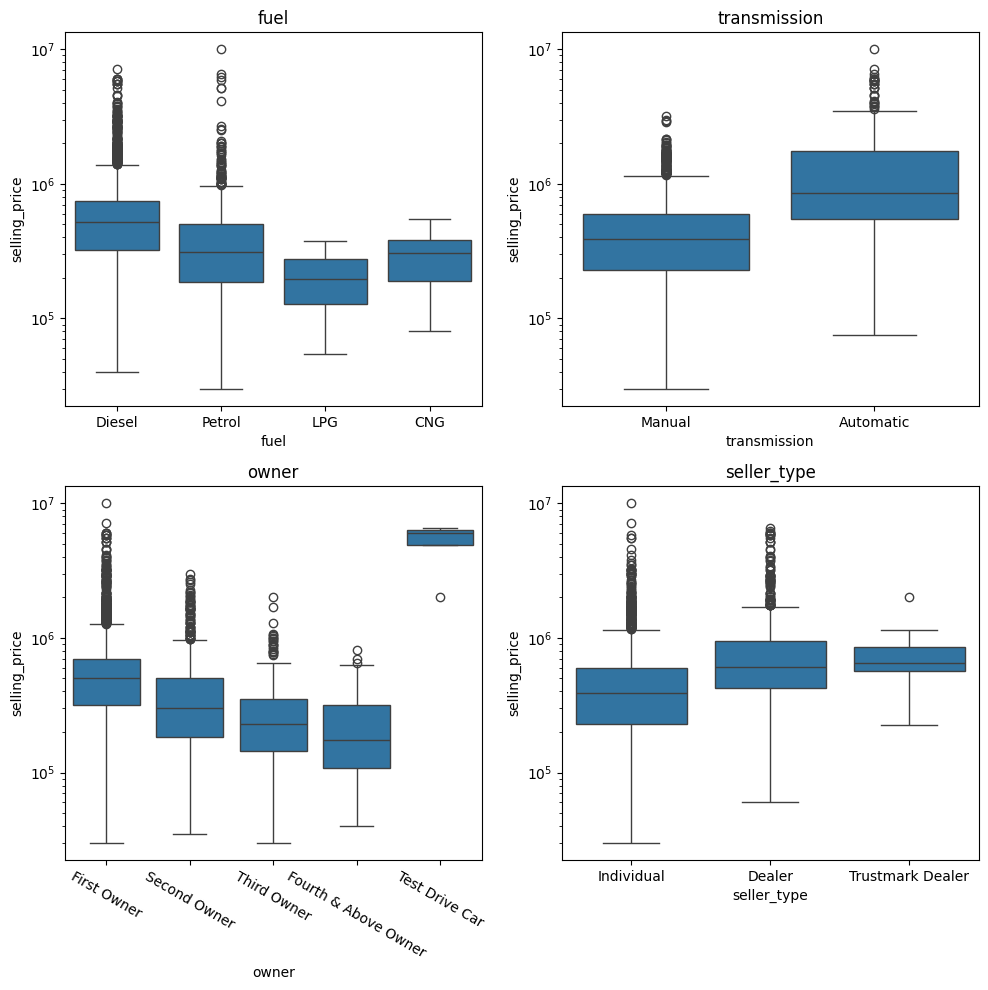

In [17]:
cat_cols = ['fuel', 'transmission', 'owner', 'seller_type']
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, col in zip(axes.flatten(), cat_cols):
    sns.boxplot(df_train, x=col, y='selling_price', ax=ax)
    ax.set_yscale('log')
    ax.set_title(col)
    if col == 'owner':
        ax.tick_params(axis='x', rotation=-30)
    
plt.tight_layout()
plt.show();

Выводы:
- По графику связи типа топлива `fuel` с таргетом видно, что у дизельных и бензиновых авто есть довольно много выбросов, а медианная цена первых выше, чем у вторых.
- По графику `transmission` видно, что цена на автомобили с автоматической коробкой передач выше, чем с механической.
- По графику предыдущих владельцев `owner` видно, что цена падает с каждой сменой владельца, а `test_drive`-авто стоят намного дороже остальных, скорее всего потому, что таких авто в целом было мало, поэтому ящик довольно маленький по сравнению с остальными, и пробег у них небольшой, поэтому цена выше.
- По графику типа продавца `seller_type` видно, что у индивидуальных продавцов медианная цена ниже остальных, но было и немало дорогих продаж; у дилеров медианная стоимость почти одинаковая, но у проверенных дилеров цены менее расходятся, чем у непроверенных, что скорее всего означает, что от проверенных диллеров продаж на вторичном рынке было меньше.

# **Часть 2 | Модель только на вещественных признаках**

В этой части вам предстоит обучить модель только на вещественных признаках. Почему только на них?

Чем больше признаковое пространство — тем сложнее модель. А чем модель проще — тем лучше для скорости работы и интерпретации признаков.

За задания этой части вы можете набрать 1.25 балла.

### **Задание 9 (0.05 балла)**

Сделайте тренировочный и тестовый наборы. Они уже даны, достаточно просто отделить целевой признак. Перед разбиением создайте копию датафрейма, который будет хранить только вещественные признаки и используйте его (то есть категориальные столбцы (все, кроме seats) необходимо удалить).

В переменные y_train и y_test запишите значения целевых переменных. Используйте уже имеющиеся данные train и test при разбиении. Если считаете уместным применить какую-то более хитрую технику разбиения — примените, но опишите, зачем.

In [18]:
df_train_numeric = df_train[numeric_cols].copy()
y_train = df_train_numeric['selling_price']
X_train = df_train_numeric.drop(['selling_price'], axis=1)

In [19]:
df_train_numeric.describe()

,year,selling_price,km_driven,mileage,engine,max_power,seats
count,5840.000000,5.840000e+03,5.840000e+03,5840.000000,5840.000000,5840.000000,5840.000000
mean,2013.428425,5.229601e+05,7.395224e+04,19.430841,1429.448973,87.906371,5.426712
std,4.095622,5.354320e+05,6.007114e+04,3.985973,485.662834,31.640418,0.982344
min,1983.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,0.000000,2.000000
25%,2011.000000,2.500000e+05,3.900000e+04,16.950000,1197.000000,68.000000,5.000000
50%,2014.000000,4.050000e+05,7.000000e+04,19.370000,1248.000000,81.860000,5.000000
75%,2017.000000,6.400000e+05,1.000000e+05,22.300000,1498.000000,99.000000,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,400.000000,14.000000


In [20]:
df_test_numeric = df_test[numeric_cols].copy()
y_test = df_test_numeric['selling_price']
X_test = df_test_numeric.drop(['selling_price'], axis=1)

In [21]:
df_test_numeric.describe()

,year,selling_price,km_driven,mileage,engine,max_power,seats
count,1000.000000,1.000000e+03,1000.000000,1000.00000,1000.00000,1000.000000,1000.000000
mean,2013.681000,6.179010e+05,71393.341000,19.33881,1454.87600,90.841670,5.403000
std,4.012149,7.585539e+05,48486.218662,3.95175,521.99574,34.893389,0.912921
min,1995.000000,3.100000e+04,1303.000000,0.00000,624.00000,34.200000,4.000000
25%,2011.000000,2.500000e+05,37000.000000,16.55000,1197.00000,69.000000,5.000000
50%,2014.000000,4.349990e+05,61500.000000,19.37000,1248.00000,82.425000,5.000000
75%,2017.000000,6.700000e+05,100000.000000,22.30000,1582.00000,102.000000,5.000000
max,2020.000000,6.000000e+06,375000.000000,32.26000,3604.00000,280.000000,9.000000


### **Задание 10 (0.2 балла)**

Построим нашу первую модель!
- [+] Обучите классическую линейную регрессию с дефолтными параметрами. Посчитайте $R^2$ и $MSE$ для трейна и для теста.
- [+] Сделайте выводы по значениям метрик качества.

**Примечание:**

Здесь и далее $R^2$ и $MSE$ для трейна и для теста выводите везде, где требуется обучать модели, даже если в явном виде этого не просят. Иначе непонятно, как понять, насколько успешны наши эксперименты.

In [22]:
y_hats = {}

In [23]:
def metrics_printer(y_train, y_hat_train, y_test, y_hat_test):
    print("Train set metrics:")
    print(f"R2: {r2_score(y_train, y_hat_train):.3f}")
    print(f"MSE: {int(MSE(y_train, y_hat_train))}")
    print(f"RMSE: {int(np.sqrt(MSE(y_train, y_hat_train)))}")
    print("\nTest set metrics:")
    print(f"R2: {r2_score(y_test, y_hat_test):.3f}")
    print(f"MSE: {int(MSE(y_test, y_hat_test))}")
    print(f"RMSE: {int(np.sqrt(MSE(y_test, y_hat_test)))}")

In [24]:
model = LinearRegression()
model.fit(X_train, y_train)

y_hat_train = model.predict(X_train)
y_hat_test = model.predict(X_test)
y_hats[str(model)[:-2]] = y_hat_test

metrics_printer(y_train, y_hat_train, y_test, y_hat_test)

Train set metrics:
R2: 0.592
MSE: 116874153930
RMSE: 341868

Test set metrics:
R2: 0.594
MSE: 233298779730
RMSE: 483010


Выводы:  
- По R2 видно, что модель объясняет 59% разбросов цен, остальные 41% остаются за другими факторами. 
- RMSE = 483010, std = 758553, ошибка стала меньше в 1.57 раза, значит польза от модели есть.

### **Задание 11 (0.15 балла)**

Всегда есть место совершенству. Поэтому давайте попробуем улучшить модель при помощи стандартизации признаков.

- [+] Стандартизируйте значения в тренировочных и тестовых данных. Стандартизатор **обучайте только на `train`**.

In [25]:
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)
y_hats[str(model)[:-2]] = y_hat_test

model.fit(X_train_scaled, y_train)
y_hat_train = model.predict(X_train_scaled)
y_hat_test = model.predict(X_test_scaled)

metrics_printer(y_train, y_hat_train, y_test, y_hat_test)

Train set metrics:
R2: 0.592
MSE: 116874153930
RMSE: 341868

Test set metrics:
R2: 0.594
MSE: 233298779730
RMSE: 483010


Как мы видим, стандартизация признаков не влияет на результат работы линейной регрессии.

### **Задание 12 (0.1 балла)**

Хотя стандартизация не помогла сильно прибавить в качестве, она открыла возможность интерпретировать важность признаков в модели. Правило интерпретации такое:

Чем больше коэффициент $\beta_i$ по модулю, тем важнее признак.

**Ответьте на вопрос:**

- [+] Какой признак оказался наиболее информативным в предсказании цены?

In [26]:
print(pd.Series(map(int, model.coef_), index=X_train.columns))

year         152772
km_driven    -44158
mileage       28833
engine        61178
max_power    322807
seats        -23209
dtype: int64


Ответ: `max_power` оказался самым значимым признаком.

### **Задание 13 (0.25 балла)**

Попробуем улучшить нашу модель с помощью применения регуляризации. Для этого воспользуемся `Lasso` регрессией.  Кроме того, попробуйте использовать её теоретическое свойство отбора признаков, за счет зануления незначимых коэффициентов.

**Задание:**

- [+] Обучите Lasso регрессию на тренировочном наборе данных со стандартизованными признаками. Оцените её качество
- [+] Проверьте, занулила ли L1-регуляризация с параметрами по умолчанию какие-нибудь веса? Предположите почему.

In [27]:
model = Lasso()
model.fit(X_train_scaled, y_train)
y_hat_train = model.predict(X_train_scaled)
y_hat_test = model.predict(X_test_scaled)
y_hats[str(model)[:-2]] = y_hat_test

metrics_printer(y_train, y_hat_train, y_test, y_hat_test)

Train set metrics:
R2: 0.592
MSE: 116874153940
RMSE: 341868

Test set metrics:
R2: 0.594
MSE: 233299450599
RMSE: 483010


Как и стандартизация признаков, Lasso-регрессия не дала прироста к точности.

In [28]:
print("Weights of Lasso regression:")
print(pd.Series(map(int, model.coef_), index=X_train.columns))

Weights of Lasso regression:
year         152772
km_driven    -44157
mileage       28832
engine        61173
max_power    322808
seats        -23206
dtype: int64


Видно, что Lasso-регрессия не занулила ни одного признака. Это произошло потому, что по умолчанию `alpha = 1`, а коэффициенты у нас измеряются в десятках тысяч. Регуляризация просто не смогла пересилить ни один коэффициент.

### **Задание 14 Финальный рывок (0.5 балла)**

До этого мы с вами использовали `train` для обучения и `test` для прогнозирования. Но у нас есть ещё одна задача — подобрать оптимальные параметры модели. Для этого используем кросс-валидацию, описанную на семинарах.

Кроме того, выжмем максимум из модификаций регрессии. Построим `ElasticNet`. И сделаем всё по порядку.

**Ваша задача 1:**

- [+] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для Lasso-регрессии. Вам пригодится класс [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [+] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какой коэффициент регуляризации у лучшей из перебранных моделей? Занулились ли какие-нибудь из весов при такой регуляризации?

In [29]:
grid = GridSearchCV(
    Lasso(), 
    param_grid={'alpha': np.logspace(-1, 5, 1000)}, 
    cv=10
)
grid.fit(X_train_scaled, y_train)

best = grid.best_estimator_
y_hat_train = best.predict(X_train_scaled)
y_hat_test = best.predict(X_test_scaled)
y_hats["Lasso_GridSearch"] = y_hat_test

print("Best alpha: ", grid.best_params_['alpha'])
print("\nLasso coefficients:")
print(pd.Series(best.coef_, index=X_train.columns))
print()
metrics_printer(y_train, y_hat_train, y_test, y_hat_test)

Best alpha:  26510.836019085364

Lasso coefficients:
year         145913.444198
km_driven    -15814.201318
mileage           0.000000
engine            0.000000
max_power    321913.272638
seats            -0.000000
dtype: float64

Train set metrics:
R2: 0.583
MSE: 119636128118
RMSE: 345884

Test set metrics:
R2: 0.565
MSE: 250271305457
RMSE: 500271


Ответы на вопросы:
- Грид-серчу пришлось обучить 10000 Lasso-моделей.
- У лучшей модели `alpha = 26510`, 3 веса занулились при таком коэффициенте: `mileage`, `engine`, `seats`.

**Ваша задача 2:**

- [+] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для [ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) регрессии.
- [+] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какие гиперпараметры соответствуют лучшей (по выбранной метрике качества) из перебранных моделей?

In [30]:
grid = GridSearchCV(
    ElasticNet(), 
    param_grid={'alpha': np.logspace(-1, 5, 100), 'l1_ratio': np.linspace(0.1, 1, 10)}, 
    cv=10
)
grid.fit(X_train_scaled, y_train)

best = grid.best_estimator_
y_hat_train = best.predict(X_train_scaled)
y_hat_test = best.predict(X_test_scaled)
y_hats["ElasticNet"] = y_hat_test

print("Best alpha: ", grid.best_params_['alpha'])
print("Best l1_ratio:", grid.best_params_['l1_ratio'])
print("\nElasticNet coefficients:")
print(pd.Series(map(int, best.coef_), index=X_train.columns))
print()
metrics_printer(y_train, y_hat_train, y_test, y_hat_test)

Best alpha:  1.4174741629268055
Best l1_ratio: 0.9

ElasticNet coefficients:
year         142898
km_driven    -46191
mileage       20759
engine        82064
max_power    269039
seats        -23252
dtype: int64

Train set metrics:
R2: 0.585
MSE: 118892053365
RMSE: 344807

Test set metrics:
R2: 0.563
MSE: 251043803891
RMSE: 501042


Ответы на вопросы:
- В этот раз грид-серч также обучил 10000 моделей ElasticNet.
- `alpha = 1.417` и `l1_ratio = 0.9` - лучшие гиперпараметры из перебранных моделей.

# **Часть 3 | Добавляем категориальные фичи**

Попробуем для улучшения модели дать ей больше признаков. Добавим категориальные фичи.

За эту часть можно набрать 0.75 балла.

**Задание 15 (0.1 балла)** Проанализируйте столбец `name`. Очевидно, что эта переменная является категориальной, однако категорий в ней много.

В этом домашнем задании мы предлагаем удалить его.

**Ваша задача:**
- [+] Создайте `X_train_cat` и `X_test_cat` — копии `df_train` и `df_test` без целевой переменной (со всеми признаками, включая категориальные)
- [+] Удалите из них столбец `name`

In [31]:
X_train_cat = df_train.drop(['selling_price', 'name'], axis=1)
X_test_cat = df_test.drop(['selling_price', 'name'], axis=1)

В другом случае, конечно, мы могли бы предобработать данный столбец (например, выделить из названия марку автомобиля). В этом задании этого делать не нужно.

In [32]:
assert X_train_cat.shape == (5840, 10)

In [33]:
X_train_cat.describe(include='object')

,fuel,seller_type,transmission,owner
count,5840,5840,5840,5840
unique,4,3,2,5
top,Diesel,Individual,Manual,First Owner
freq,3177,5223,5336,3603


### **Задание 16 (0.4 балла)**

- [+] Закодируйте категориальные фичи и ``seats`` методом OneHot-кодирования. Обратите внимание, что во избежание мультиколлинеарности следует избавиться от одного из полученных столбцов при кодировании каждого признака методом OneHot.

In [34]:
all_ohe = pd.get_dummies(
    pd.concat([X_train_cat, X_test_cat]),
    columns=cat_cols + ['seats'], drop_first=True, dtype=int
)
X_train_cat = all_ohe.iloc[:len(X_train_cat)]
X_test_cat = all_ohe.iloc[len(X_train_cat):]

### **Задание 17 (0.25 балла)**
Повторим то, что делали на прошлом шаге для моделей на вещественных признаках, однако теперь с моделью `Ridge`.


**Ваша задача:**
- [+] Переберите параметр регуляризации `alpha` для гребневой (ridge) регрессии с помощью класса `GridSearchCV`. В качестве параметров при объявлении GridSearchCV кроме модели укажите метрику качества $R^2$. Кроссвалидируйтесь по 10-ти фолдам.
- [+] Ответьте на вопрос: Удалось ли улучшить качество прогнозов?

In [35]:
grid = GridSearchCV(
    Ridge(), 
    param_grid={'alpha': np.linspace(1, 10, 1000)}, 
    cv=10,
    scoring="r2")
grid.fit(X_train_cat, y_train)

best = grid.best_estimator_
y_hat_train = best.predict(X_train_cat)
y_hat_test = best.predict(X_test_cat)
y_hats["Ridge"] = y_hat_test

print("Best alpha: ", grid.best_params_['alpha'])
print("\nRidge coefficients:")
print(pd.Series(best.coef_, index=X_train_cat.columns))
print()
metrics_printer(y_train, y_hat_train, y_test, y_hat_test)

Best alpha:  7.009009009009009

Ridge coefficients:
year                            3.623827e+04
km_driven                      -5.049943e-01
mileage                         8.250067e+03
engine                          7.924589e+01
max_power                       9.106423e+03
fuel_Diesel                     2.268433e+04
fuel_LPG                        1.271610e+05
fuel_Petrol                    -3.310245e+04
transmission_Manual            -2.906734e+05
owner_Fourth & Above Owner     -3.809234e+04
owner_Second Owner             -5.331399e+04
owner_Test Drive Car            1.190748e+06
owner_Third Owner              -3.660449e+04
seller_type_Individual         -1.106828e+05
seller_type_Trustmark Dealer   -1.057710e+05
seats_4                         4.593043e+05
seats_5                        -9.363348e+04
seats_6                        -1.587474e+05
seats_7                        -8.716389e+04
seats_8                        -4.601565e+04
seats_9                        -4.873422e+04
sea

Ответ: да, качество прогнозов удалось улучшить благодаря добавлению категориальных признаков на 0.051 по сравнению с лучшим результатом у линейной регрессии.

# **Часть 4 | Бизнесовая (0.5 балла)**

### **Задание 18 (0.5 балла)**

В мире бизнеса очень важно давать оценку качества модели понятную бизнесу, поэтому иногда заказчики приходят с кастомными метриками. Попробуем сделать такую для нашей задачи.

**Описание метрики:**

Среди всех предсказанных цен на авто нужно посчитать долю прогнозов, отличающихся от реальных цен на эти авто не более чем на 10% (в одну или другую сторону). Отклонение считается относительно **реальной** цены $y_i$:

$$\text{business\_metric}(y, \hat y) = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\frac{|\hat y_i - y_i|}{y_i} \le 0.1\right]$$

**Ваша задача:**

- [+] Реализуйте метрику `business_metric`
- [+] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

In [36]:
def business_metric(y_true, y_pred):
    n = len(y_true)
    return float(np.sum(np.abs(y_pred - y_true)/y_true <= 0.1)/n)

for model, y_hat_test in y_hats.items():
    result = business_metric(y_test, y_hat_test)
    print(f"Model {model}, business_metric: {result}")

Model LinearRegression, business_metric: 0.227
Model Lasso, business_metric: 0.227
Model Lasso_GridSearch, business_metric: 0.233
Model ElasticNet, business_metric: 0.242
Model Ridge, business_metric: 0.245


Ответ: лучше всего задачу бизнеса решает Ridge модель на данных с категориальными признаками.

# **Часть 5 | Оформление репозитория (2 балла)**

Домашнее задание оформите как репозиторий на GitHub.

---

### Обязательные файлы:

1. **`.ipynb`-ноутбук** со всеми экспериментами (0.5 балла):

   * полный EDA,
   * все шаги препроцессинга,
   * обучение и сравнение моделей,
   * сохранённые output’ы;
   * ноутбук запускается сверху вниз без ошибок.

2. **`.pickle`-файл** (0.5 балла), содержащий:

   * обученную модель (или пайплайн `scaler + model`);
   * параметры скейлинга;
   * любые числовые объекты, необходимые для инференса внутри Streamlit-приложения.

   Файл должен загружаться и делать предсказание на новых объектах.

3. **`.md`-файл с выводами** о проделанной работе (1 балл):

   * что было сделано (краткое описание каждого этапа), какие результаты были получены (метрики + интерпретация), что дало наибольший прирост качества (0.75 балла);
   * что сделать не удалось и почему — это нормально и даже полезно (0.25 балла).


### **За что могут быть сняты баллы:**

* отсутствие `.pickle` с моделью / пайплайном;
* слабая или неполная аналитика в `.md`-файле;
* беспорядок в ноутбуке или неясная логика вычислений.

In [37]:
medians = df_train[numeric_cols].median().to_dict()

In [38]:
import pickle

artifacts = {
    'model': best,
    'columns': list(X_train_cat.columns),
    'medians': medians,
    'categories': {c: sorted(df_train[c].unique().tolist()) for c in cat_cols},
}

with open('model.pickle', 'wb') as f:
    pickle.dump(artifacts, f)

In [39]:
with open('model.pickle', 'rb') as f:
    file = pickle.load(f)

def predict_price(row: dict):
    df = pd.DataFrame([row])
    for col, med in file['medians'].items():
        if col in df.columns:
            df[col] = df[col].fillna(med)
    df['seats'] = df['seats'].astype(int)
    df = pd.get_dummies(df, columns=cat_cols + ['seats'], dtype=int)
    df = df.reindex(columns=file['columns'], fill_value=0)
    return file['model'].predict(df)[0]

example = {
    'year': 2015, 'km_driven': 60000, 'fuel': 'Diesel',
    'seller_type': 'Individual', 'transmission': 'Manual',
    'owner': 'First Owner', 'mileage': 20.0, 'engine': 1248,
    'max_power': 80.0, 'seats': 5,
}
print(predict_price(example))

499473.3411553204


# **<font color="green">Часть 6 | Создание интерактивного приложения на Streamlit (3 балла)</font>**

Вам необходимо создать интерактивное приложение на Streamlit (например, `app.py`), которое запускается командой

```bash
streamlit run app.py
```

и опубликовать его в [Streamlit Community Cloud](https://streamlit.io/cloud). Приложение должно:

- показывать основные информативные графики/гистограммы в рамках EDA (0.75 балла);
- на вход запрашивать csv-файл с признаками объектов или запрашивать признаки объекта в окошках для ввода, и применять на поступивших объектах модель из `.pickle`-файла (1 балл);
- визуализировать веса (коэффициенты) обученной модели (0.75 балла).

**Оценка сервиса (0.5 балла).** Дополните `.md`-файл из Части 5 разделом об оценке приложения:

* насколько приложение удобно в использовании;
* что получилось визуализировать хорошо, а что — менее удачно;
* какие ограничения или проблемы вы заметили;
* какие улучшения планируете в следующей итерации.

**Что нужно сдать:** код приложения в репозитории из Части 5 и ссылку на приложение в Streamlit Community Cloud.

**За что могут быть сняты баллы:** приложение не запускается командой выше или ссылка на него не открывается.